<a href="https://colab.research.google.com/github/anitejpadyana/BIS-lab/blob/main/Ant_Colony_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best tour (city numbering starts at 1):
2 -> 6 -> 1 -> 8 -> 3 -> 5 -> 7 -> 4 -> 2
Best tour length: 25.03


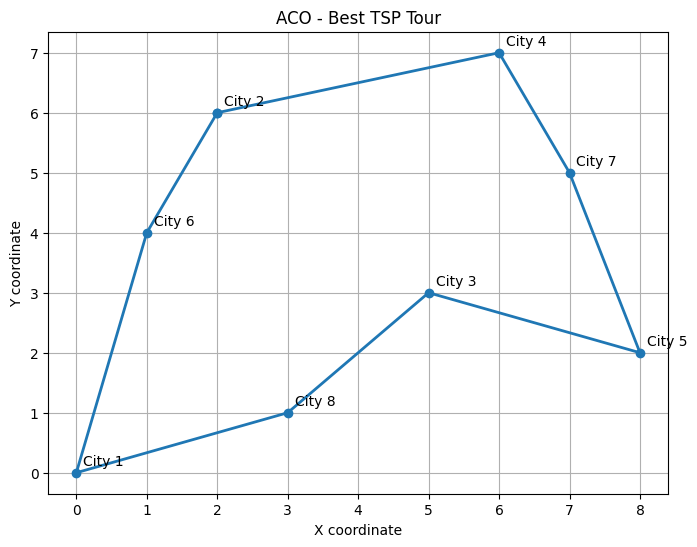

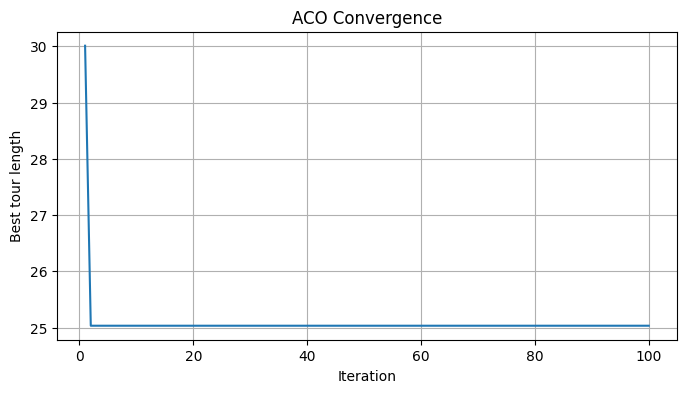

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def ant_colony_optimization_tsp(
    distances, m=10, alpha=1.0, beta=2.0,
    rho=0.5, Q=100, MaxIter=100, seed=42
):
    rng = np.random.default_rng(seed)
    n = len(distances)


    tau = np.ones((n, n))
    np.fill_diagonal(tau, 0)

    eta = np.zeros((n, n))
    mask = distances > 0
    eta[mask] = 1 / distances[mask]

    best_tour = None
    best_length = float("inf")
    history = []

    for iteration in range(MaxIter):
        tours = []
        lengths = []


        for k in range(m):
            start = int(rng.integers(n))
            tour = [start]
            visited = {start}
            current = start

            while len(visited) < n:
                candidates = [
                    j for j in range(n) if j not in visited
                ]

                weights = np.array([
                    tau[current, j]**alpha *
                    eta[current, j]**beta
                    for j in candidates
                ])

                if weights.sum() == 0 or not np.isfinite(weights).all():
                    probabilities = np.ones(len(candidates)) / len(candidates)
                else:
                    probabilities = weights / weights.sum()

                next_city = int(rng.choice(candidates, p=probabilities))
                tour.append(next_city)
                visited.add(next_city)
                current = next_city


            tour.append(start)

            length = sum(
                distances[tour[i], tour[i + 1]]
                for i in range(len(tour) - 1)
            )

            tours.append(tour)
            lengths.append(length)

            if length < best_length:
                best_length = length
                best_tour = tour.copy()


        tau *= (1 - rho)


        for tour, length in zip(tours, lengths):
            if length > 0:
                deposit = Q / length

                for i in range(len(tour) - 1):
                    a, b = tour[i], tour[i + 1]
                    tau[a, b] += deposit
                    tau[b, a] += deposit

        history.append(best_length)

    return best_tour, best_length, history


cities = np.array([
    [0, 0],
    [2, 6],
    [5, 3],
    [6, 7],
    [8, 2],
    [1, 4],
    [7, 5],
    [3, 1]
], dtype=float)


n = len(cities)
distances = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        distances[i, j] = np.linalg.norm(cities[i] - cities[j])


best_tour, best_length, history = ant_colony_optimization_tsp(
    distances,
    m=10,
    alpha=1,
    beta=2,
    rho=0.5,
    Q=100,
    MaxIter=100
)

print("Best tour (city numbering starts at 1):")
print(" -> ".join(str(city + 1) for city in best_tour))
print("Best tour length:", round(best_length, 2))


route = cities[best_tour]

plt.figure(figsize=(8, 6))
plt.plot(route[:, 0], route[:, 1], marker="o", linewidth=2)

for i, (x, y) in enumerate(cities):
    plt.annotate(f"City {i + 1}", (x, y), xytext=(5, 5),
                 textcoords="offset points")

plt.title("ACO - Best TSP Tour")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history) + 1), history)
plt.title("ACO Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best tour length")
plt.grid(True)
plt.show()
